# 01 · Exploratory data analysis

**Question:** can in-line sensor readings flag defective semiconductor wafers before the final electrical test?

This notebook explores the UCI SECOM dataset: its size, class balance, missing values and redundancy.
Everything after the initial overview is computed on the **training split only**, so no information from the
test set shapes later decisions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from secom.config import FIGURES_DIR, NAN_THRESHOLD
from secom.data import load_secom, split

sns.set_theme(style="whitegrid", context="notebook")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. The dataset

In [2]:
X, y, timestamp = load_secom()
print(f"{X.shape[0]:,} wafers x {X.shape[1]} sensors")
print(f"Recorded {timestamp.min():%d %b %Y} to {timestamp.max():%d %b %Y}")
print(f"Missing values: {X.isna().sum().sum():,} ({X.isna().mean().mean():.2%} of all cells)")
print(f"Duplicate rows: {X.duplicated().sum()}")
y.value_counts().rename(index={0: "pass", 1: "fail"}).to_frame("wafers").assign(
    share=lambda d: d.wafers / d.wafers.sum()
)

1,567 wafers x 590 sensors
Recorded 19 Jul 2008 to 17 Oct 2008
Missing values: 41,951 (4.54% of all cells)
Duplicate rows: 0


,wafers,share
fail,,
pass,1463,0.933631
fail,104,0.066369


Only **6.6 %** of wafers fail. A model that always predicts *pass* would be 93 % accurate and useless, so
accuracy is not a meaningful metric here; the project uses recall, ROC-AUC and a business cost instead.

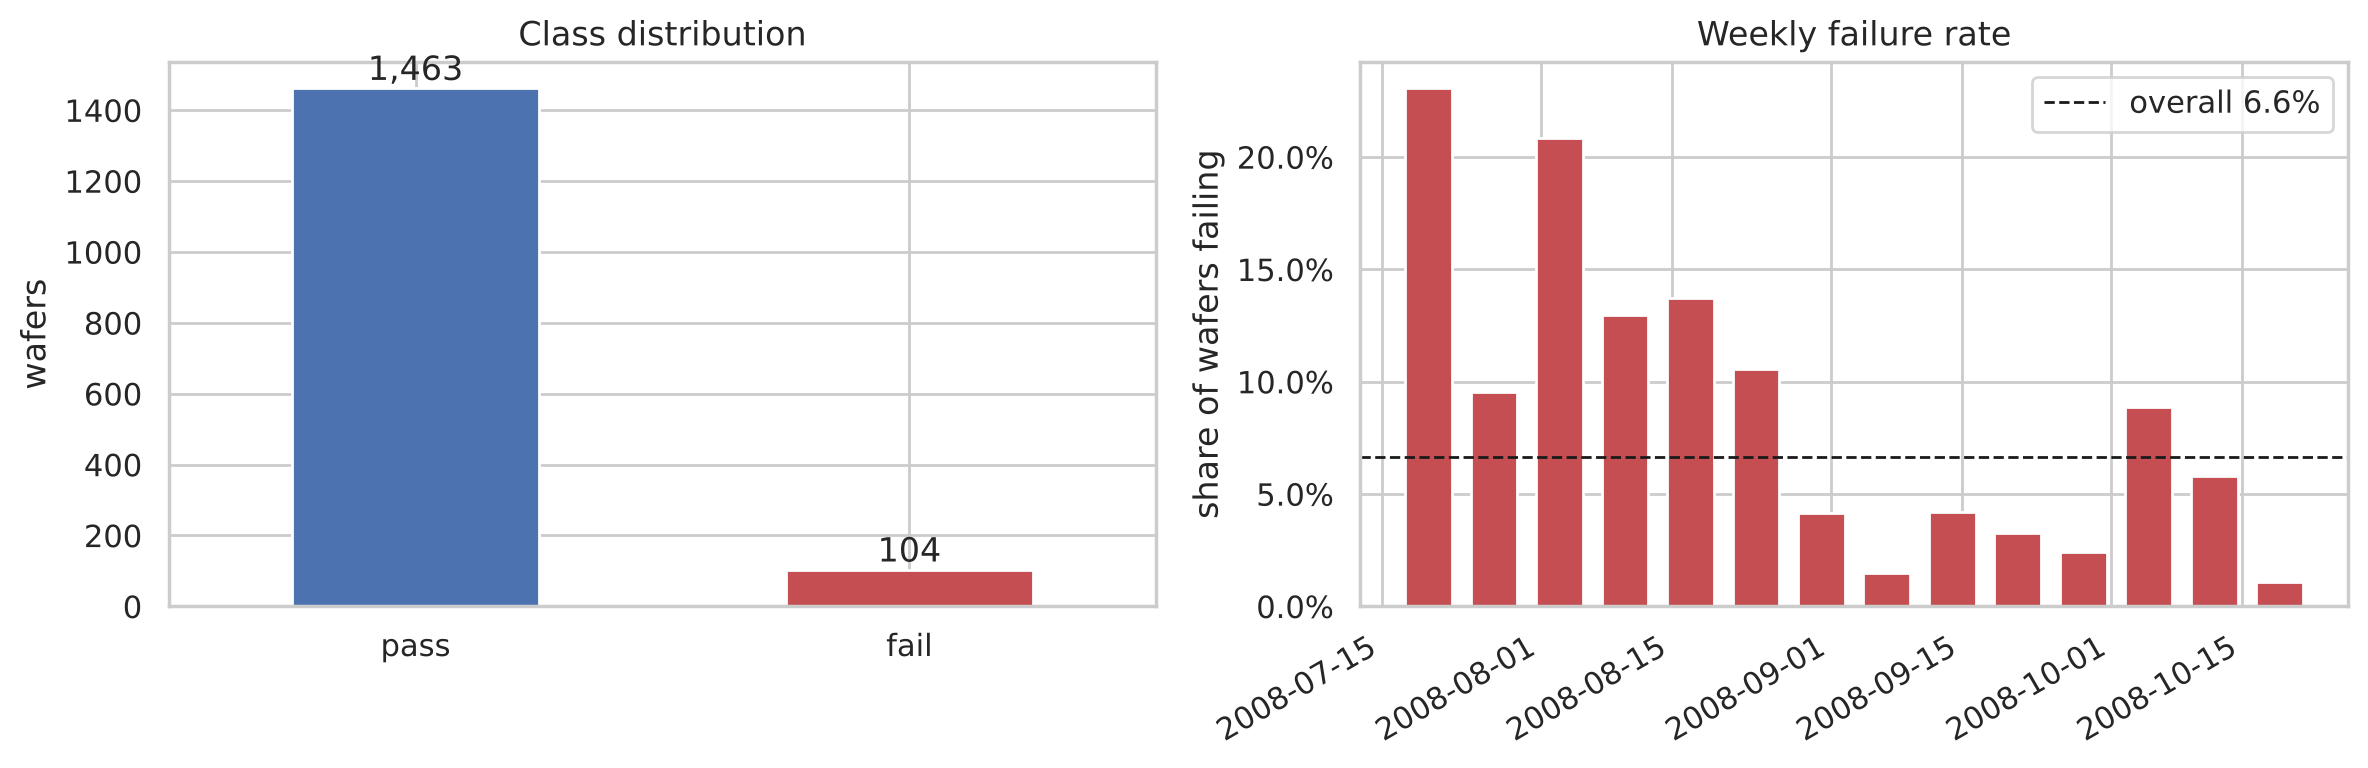

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y.map({0: "pass", 1: "fail"}).value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#C44E52"], rot=0)
axes[0].set(title="Class distribution", ylabel="wafers", xlabel="")
for p in axes[0].patches:
    axes[0].annotate(
        f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom"
    )

weekly = pd.DataFrame({"fail": y.values}, index=timestamp).resample("W")["fail"].agg(["mean", "size"])
axes[1].bar(weekly.index, weekly["mean"], width=5, color="#C44E52")
axes[1].axhline(y.mean(), color="k", ls="--", lw=1, label=f"overall {y.mean():.1%}")
axes[1].set(title="Weekly failure rate", ylabel="share of wafers failing")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].legend()
plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_class_balance.png", dpi=150)

The failure rate drops sharply over the recording period (from 10-20 % in July/August to a few percent in
September/October), a sign of process drift. The project keeps the random stratified split of the original
course work, so train and test cover the same period; a time-based split is the more realistic test and is listed
as a next step in the README.

## 2. Train/test split

The split happens **before** any cleaning, so that thresholds, scalers, imputers and feature selection are all
learned from training data only.

In [4]:
X_train, X_test, y_train, y_test = split(X, y)
pd.DataFrame(
    {
        "wafers": [len(y_train), len(y_test)],
        "fails": [y_train.sum(), y_test.sum()],
        "fail rate": [y_train.mean(), y_test.mean()],
    },
    index=["train", "test"],
)

,wafers,fails,fail rate
train,1253,83,0.066241
test,314,21,0.066879


## 3. Unusable sensors

In [5]:
constant = X_train.columns[X_train.nunique(dropna=True) <= 1]
nan_ratio = X_train.drop(columns=constant).isna().mean()
sparse = nan_ratio.index[nan_ratio > NAN_THRESHOLD]
usable = X_train.shape[1] - len(constant) - len(sparse)
print(f"Constant (zero-variance) sensors: {len(constant)}")
print(f"Sensors with > {NAN_THRESHOLD:.0%} missing values: {len(sparse)}")
print(f"Usable sensors: {usable}")
print(f"Missing values left in usable sensors: {X_train.drop(columns=constant.union(sparse)).isna().sum().sum():,}")

Constant (zero-variance) sensors: 116
Sensors with > 60% missing values: 24
Usable sensors: 450
Missing values left in usable sensors: 11,211


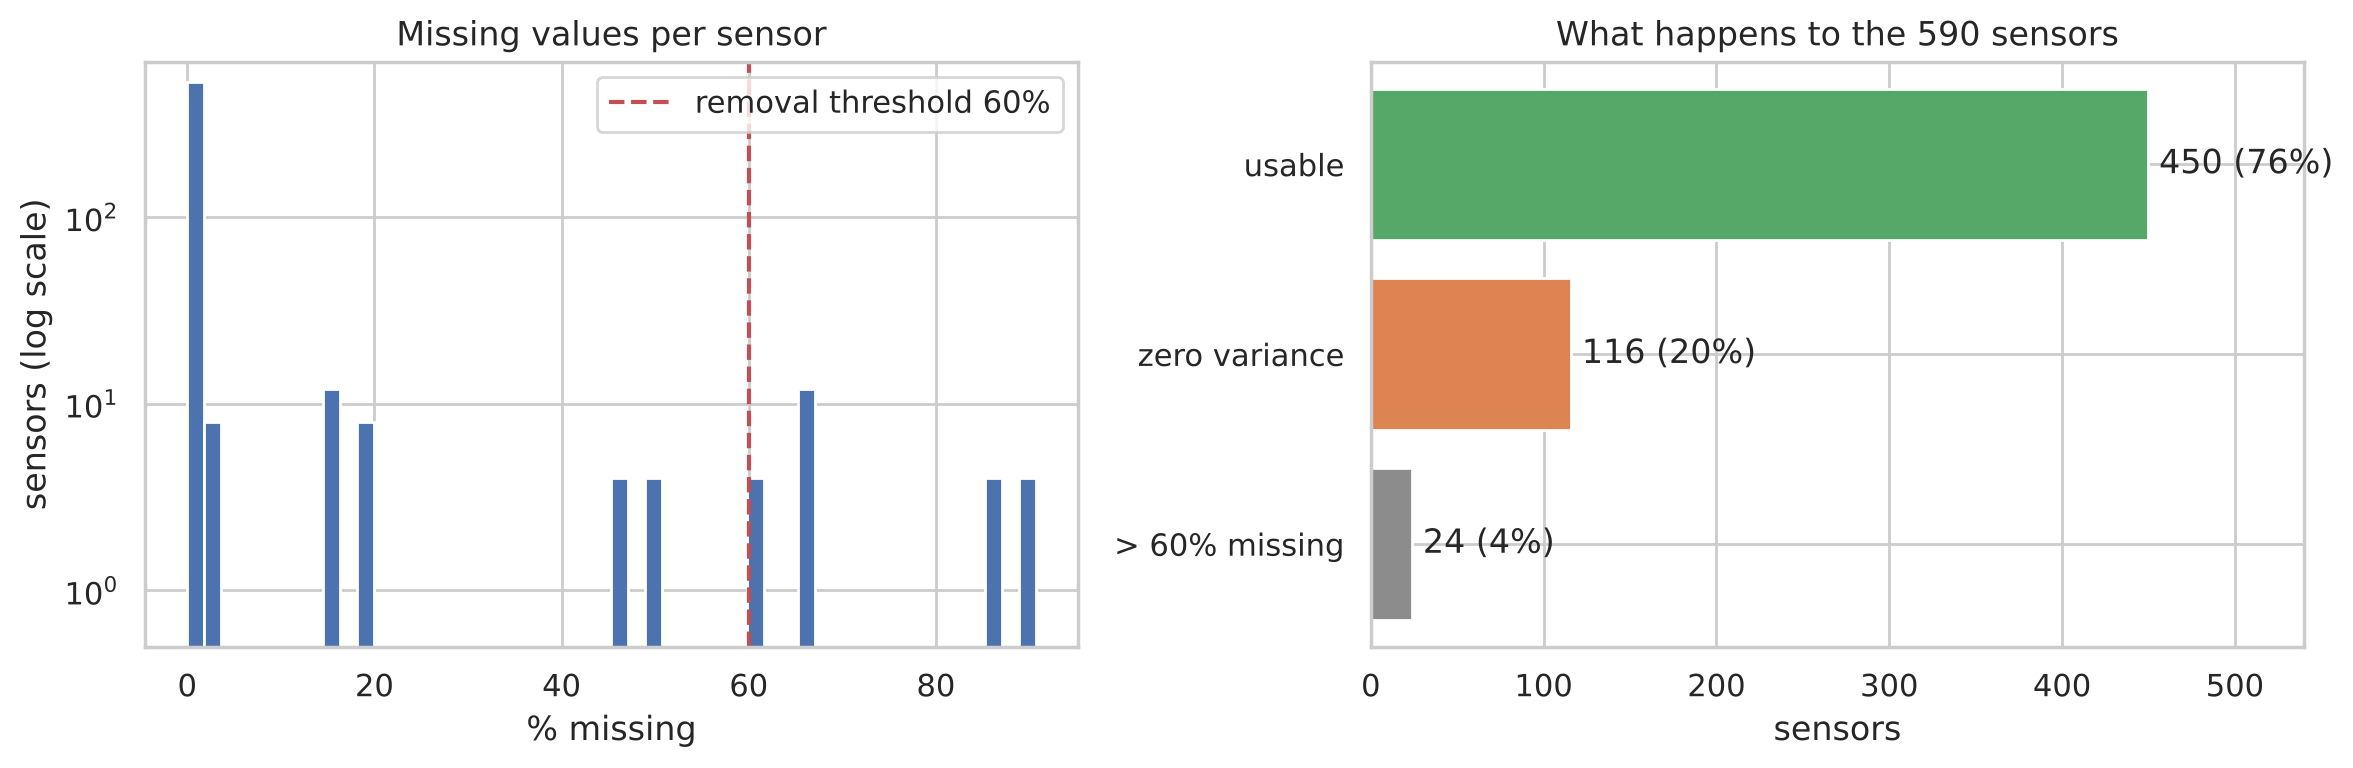

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train.isna().mean() * 100, bins=50, color="#4C72B0")
axes[0].axvline(NAN_THRESHOLD * 100, color="#C44E52", ls="--", label=f"removal threshold {NAN_THRESHOLD:.0%}")
axes[0].set(
    title="Missing values per sensor", xlabel="% missing", ylabel="sensors (log scale)", yscale="log", ylim=(0.5, None)
)
axes[0].legend()

parts = pd.Series({"usable": usable, "zero variance": len(constant), f"> {NAN_THRESHOLD:.0%} missing": len(sparse)})
axes[1].barh(parts.index[::-1], parts.values[::-1], color=["#8C8C8C", "#DD8452", "#55A868"])
for i, v in enumerate(parts.values[::-1]):
    axes[1].text(v, i, f" {v} ({v / X_train.shape[1]:.0%})", va="center")
axes[1].set(title="What happens to the 590 sensors", xlabel="sensors")
axes[1].margins(x=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_sensor_overview.png", dpi=150)

## 4. Scale, outliers and redundancy

Sensor values span many orders of magnitude and units are unknown, so scaling is needed before
distance-based steps such as kNN imputation.

In [7]:
X_use = X_train.drop(columns=constant.union(sparse))
X_use.describe().T[["mean", "std", "min", "max"]].sample(8, random_state=1)

,mean,std,min,max
s585,3.098152,3.969051,1.2845,99.3032
s460,29.170373,13.518194,8.0728,149.3851
s174,0.320159,0.070937,0.1287,0.4946
s098,-0.028016,0.422750,-5.2717,2.5450
s051,157.642693,60.365034,40.2614,258.5432
s365,0.005145,0.002542,0.0020,0.0368
s073,468.393987,19.297102,456.0447,692.4256
s493,2.541810,0.966803,0.8614,7.6479


In [8]:
z = (X_use - X_use.mean()) / X_use.std()
share_out = (z.abs() > 3).sum().sum() / X_use.notna().sum().sum()
print(f"{share_out:.2%} of observed values lie beyond 3 standard deviations")
print(f"{((z.abs() > 3).any()).mean():.0%} of usable sensors contain at least one such value")

0.88% of observed values lie beyond 3 standard deviations
92% of usable sensors contain at least one such value


Sensor pairs with |r| > 0.95: 277


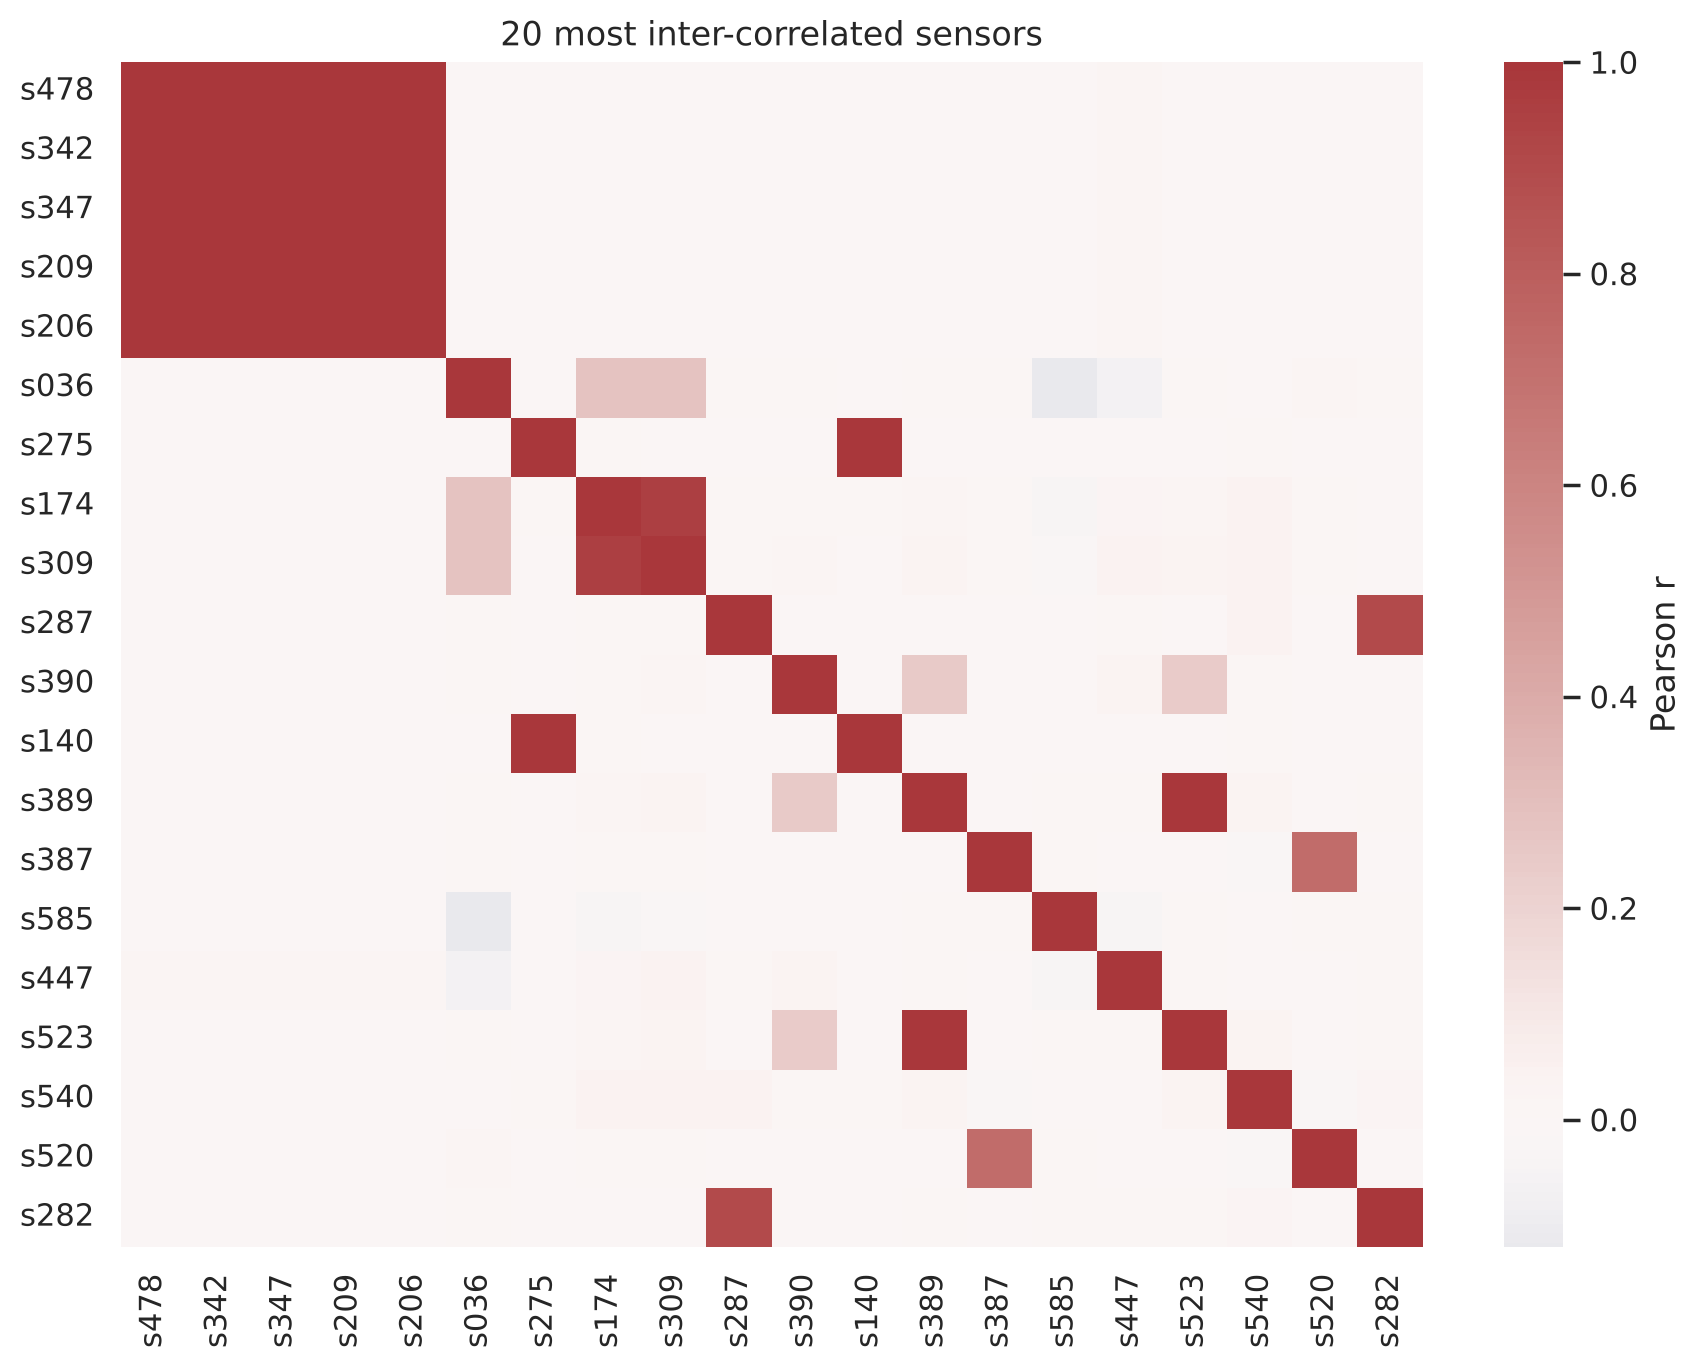

In [9]:
corr = X_use.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
print(f"Sensor pairs with |r| > 0.95: {(upper > 0.95).sum().sum()}")

top = upper.max().sort_values(ascending=False).index[:20]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(X_use[top].corr(), cmap="vlag", center=0, ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("20 most inter-correlated sensors")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_correlation.png", dpi=150)

## Takeaways

| Finding | Consequence for the pipeline |
|---|---|
| 6.6 % failures | judge models by recall, ROC-AUC and cost; try oversampling |
| 116 constant and 24 mostly-empty sensors | drop them (fitted on training folds) |
| ~2 % missing values remain | kNN imputation after scaling |
| very different scales, many 3σ outliers | compare scalers and outlier strategies |
| many near-duplicate sensors | model-based feature selection (Boruta), which keeps original, interpretable sensors |

Next: [02 · Preprocessing and feature selection](02_preprocessing_feature_selection.ipynb)